# 06 · Avaliação no instante do registro (v3)
**CRISP-DM:** Avaliação · **RQ1, RQ2, RQ3**

Para cada cenário, no instante do registro:
1. **Estado** do período [t − L, t) com L = 15 (principal), 30 e 60 min: Normal ou Residual;
2. **Indicador responsável** (4xx, 5xx, latência ou volume) quando Residual;
3. **Início**: expansão retroativa (0–15, 15–30, 30–60 min, depois de 1 h em 1 h até 4 h) até a primeira faixa Normal;
4. **Abrangência** (complementar): consumidor específico ou generalizado.

Cada cenário é decidido com o modelo do seu **mês de teste** (agosto ou setembro), ajustado só com dados anteriores. O histórico principal é de **3 meses**; o de **1 mês** é comparado na seção própria. "Média/alta" = intensidades média e alta (comparável à v2); a latência ×10 é relatada à parte.

Métricas: sensibilidade (incidentes com saída Residual), especificidade (controles com saída Normal), acurácia do indicador, acerto da zona de início, com **IC de Wilson (95%)**; comparação com os baselines pelo **teste de McNemar** (mesmos casos).

In [1]:
%run ./00_funcoes.ipynb

00_funcoes (v6) carregado · /home/wsl/gh/mestrado/claude9/v6


In [2]:
import pickle
import time
with open(RESULTADOS / "04_calibracao.pkl", "rb") as f:
    calib = pickle.load(f)
cenarios = pd.read_csv(RESULTADOS / "05_cenarios.csv", parse_dates=["t_registro"])
brutos = pd.read_parquet(RESULTADOS / "02_brutos_consolidados.parquet")
B = Brutos(brutos)

## Períodos de todos os cenários

In [3]:
t_ini = time.time()
linhas = []
for cen in cenarios.itertuples():
    linhas.extend(periodos_do_cenario(B, cen))
P = pd.DataFrame(linhas)
print(f"{len(P):,} períodos em {time.time() - t_ini:.0f} s")
# incidentes sem nenhum tráfego no intervalo degradado (lacunas nos dados) ficam fora das métricas
sem_traf = set(P.loc[P["sem_trafego"], "cenario"])
print(f"incidentes sem tráfego no intervalo degradado (excluídos): {len(sem_traf)}")
cenarios = cenarios[~cenarios["cenario"].isin(sem_traf)].reset_index(drop=True)
P = P[~P["cenario"].isin(sem_traf)].reset_index(drop=True)

109,440 períodos em 456 s
incidentes sem tráfego no intervalo degradado (excluídos): 3


## Decisão por método e faixa

In [4]:
cen_mes = cenarios.set_index("cenario")["mes"]


def decidir_mes(sub, nome, L, hist):
    """Decide cada período com a calibração do mês de teste do seu cenário."""
    partes = []
    chave = sub["cenario"].to_numpy() if "cenario" in sub.columns else sub.index.to_numpy()
    for mes, g in sub.groupby(cen_mes.reindex(chave).to_numpy()):
        res, ind, vz = decidir(g, calib[(nome, L, mes, hist)])
        partes.append(pd.DataFrame({"residual": res, "indicador": ind.to_numpy()}, index=g.index).join(vz.add_prefix("vz_")))
    return pd.concat(partes).reindex(sub.index)


dec = {}
for hist in HISTORICOS:
    for nome in METODOS:
        for L in FAIXAS_L:
            sub = P[(P["periodo"] == "L") & (P["id_periodo"] == L)].set_index("cenario")
            dec[(nome, L, hist)] = decidir_mes(sub, nome, L, hist)[["residual", "indicador"]]

# bandas da expansão retroativa (método proposto, histórico principal), cada uma com o limite do seu tamanho
bandas = P[P["periodo"] == "banda"].copy()
bandas["L"] = bandas["hi"] - bandas["lo"]
bandas["residual"] = False
for L in FAIXAS_L:
    m = (bandas["L"] == L).to_numpy()
    bandas.loc[m, "residual"] = decidir_mes(bandas[m], PROPOSTO, L, HIST_PRINCIPAL)["residual"].to_numpy()
res_bandas = bandas.pivot(index="cenario", columns="id_periodo", values="residual")
inicio = pd.DataFrame([estimar_inicio(list(v)) for v in res_bandas.to_numpy()], index=res_bandas.index,
                      columns=["estado_bandas", "zona_lo", "zona_hi"])


def tabela(nome, L, hist):
    t = cenarios.set_index("cenario").join(dec[(nome, L, hist)])
    t["esperado"] = t["motivo"].map(lambda m: MOTIVOS[m][0] if isinstance(m, str) else None)
    t["abr_esperada"] = t["motivo"].map(lambda m: MOTIVOS[m][1] if isinstance(m, str) else None)
    t["acerto_estado"] = np.where(t["tipo"] == "incidente", t["residual"], ~t["residual"])
    return t


T_all = {(n, L, h): tabela(n, L, h) for n in METODOS for L in FAIXAS_L for h in HISTORICOS}
T = {(n, L): T_all[(n, L, HIST_PRINCIPAL)] for n in METODOS for L in FAIXAS_L}  # histórico principal (3 meses)
inc = lambda t: t[t["tipo"] == "incidente"]
ctl = lambda t: t[t["tipo"] == "controle"]

## RQ1 · Estado no instante do registro

In [5]:
linhas = []
for (n, L), t in T.items():
    i, c = inc(t), ctl(t)
    i_mf = i[i["intensidade"].isin(["media", "alta"])]
    linhas.append(dict(metodo=n, L=L,
                       sensibilidade=fmt_ic(int(i["residual"].sum()), len(i)),
                       sens_media_alta=fmt_ic(int(i_mf["residual"].sum()), len(i_mf)),
                       especificidade=fmt_ic(int((~c["residual"]).sum()), len(c)),
                       sens=i["residual"].mean(), sens_ma=i_mf["residual"].mean(), espec=(~c["residual"]).mean()))
resumo = pd.DataFrame(linhas)
resumo[["metodo", "L", "sensibilidade", "sens_media_alta", "especificidade"]]

,metodo,L,sensibilidade,sens_media_alta,especificidade
0,Perfil contextual (proposto),15,70.3% [69.1%; 71.4%],74.6% [73.2%; 76.0%],79.1% [78.1%; 80.1%]
1,Perfil contextual (proposto),30,67.6% [66.5%; 68.8%],73.0% [71.6%; 74.4%],81.5% [80.5%; 82.5%]
2,Perfil contextual (proposto),60,63.1% [61.9%; 64.3%],69.2% [67.7%; 70.7%],81.9% [80.9%; 82.8%]
3,z-score global,15,65.5% [64.3%; 66.7%],70.0% [68.5%; 71.4%],86.6% [85.7%; 87.4%]
4,z-score global,30,64.1% [62.9%; 65.3%],69.7% [68.2%; 71.1%],87.1% [86.3%; 88.0%]
5,z-score global,60,58.9% [57.7%; 60.1%],65.1% [63.6%; 66.6%],86.0% [85.1%; 86.8%]
6,Semana anterior,15,65.0% [63.8%; 66.2%],69.9% [68.4%; 71.3%],87.0% [86.1%; 87.8%]
7,Semana anterior,30,63.7% [62.5%; 64.9%],69.5% [68.0%; 70.9%],87.2% [86.3%; 88.0%]
8,Semana anterior,60,59.7% [58.5%; 60.9%],65.9% [64.4%; 67.4%],85.5% [84.6%; 86.4%]


### Comparação com os baselines (McNemar, mesmos casos)

In [6]:
mc = []
for L in FAIXAS_L:
    a = T[(PROPOSTO, L)]["acerto_estado"]
    for b in METODOS:
        if b == PROPOSTO:
            continue
        n01, n10, p = mcnemar(a, T[(b, L)].loc[a.index, "acerto_estado"])
        mc.append(dict(L=L, baseline=b, so_proposto_acerta=n01, so_baseline_acerta=n10, p=p))
mc = pd.DataFrame(mc)
mc

,L,baseline,so_proposto_acerta,so_baseline_acerta,p
0,15,z-score global,730,892,0.000063
1,15,Semana anterior,887,1042,0.000451
2,30,z-score global,668,793,0.001171
3,30,Semana anterior,792,898,0.010624
4,60,z-score global,769,762,0.878134
5,60,Semana anterior,853,865,0.790720


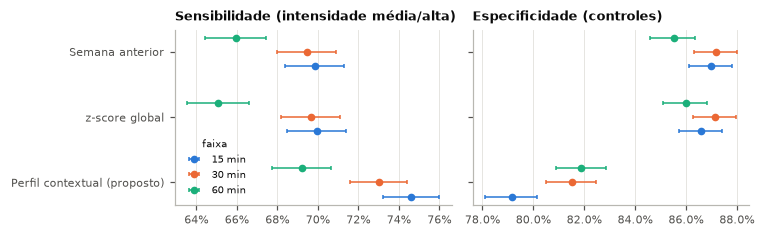

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.2), sharey=True)
metodos = list(METODOS)
for ax, (col, titulo) in zip(axes, [("sens_ma", "Sensibilidade (intensidade média/alta)"), ("espec", "Especificidade (controles)")]):
    for j, L in enumerate(FAIXAS_L):
        for i, n in enumerate(metodos):
            t = T[(n, L)]
            base = inc(t)[inc(t)["intensidade"].isin(["media", "alta"])] if col == "sens_ma" else ctl(t)
            k = int(base["residual"].sum()) if col == "sens_ma" else int((~base["residual"]).sum())
            p = k / len(base)
            lo, hi = wilson(k, len(base))
            y = i + (j - 1) * 0.22
            ax.errorbar(p, y, xerr=[[p - lo], [hi - p]], fmt="o", ms=4, color=CORES[j], ecolor=CORES[j], lw=1,
                        capsize=1.5, label=f"{L} min" if i == 0 else None)
    ax.set_yticks(range(len(metodos)))
    ax.set_yticklabels(metodos)
    ax.invert_yaxis()
    ax.set_title(titulo, loc="left")
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0 if col == "sens_ma" else 1))
    ax.grid(axis="y", visible=False)
axes[0].legend(title="faixa", loc="lower left", fontsize=6.5, title_fontsize=6.5)
fig.tight_layout()
salvar(fig, "fig_metodos")
plt.show()

### Sensibilidade por motivo e intensidade (método proposto, 15 min)

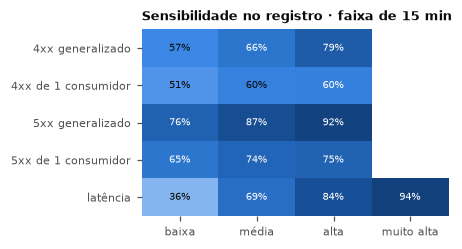

,baixa,média,alta,muito alta
motivo,,,,
4xx generalizado,0.567,0.658,0.787,NaN
4xx de 1 consumidor,0.509,0.596,0.603,NaN
5xx generalizado,0.755,0.866,0.924,NaN
5xx de 1 consumidor,0.653,0.739,0.753,NaN
latência,0.363,0.692,0.845,0.937


In [8]:
t15 = inc(T[(PROPOSTO, L_PRINCIPAL)])
sm = t15.groupby(["motivo", "intensidade"])["residual"].mean().unstack()[INTENSIDADES]
sm.index = sm.index.map(NOMES_MOTIVO)
sm = sm.loc[[NOMES_MOTIVO[m] for m in MOTIVOS]]
sm.columns = ["baixa", "média", "alta", "muito alta"]
fig, ax = plt.subplots(figsize=(3.6, 2.2))
heatmap(ax, sm)
ax.set_title("Sensibilidade no registro · faixa de 15 min", loc="left")
salvar(fig, "fig_sens_motivo")
plt.show()
sm.round(3)

## Ponto de operação: 1%, 2% e 5% de alarmes no histórico
Mesmos limites-base (percentil 99 por indicador), variando o multiplicador c. A meta adotada é 5% (c = 1). Histórico de 3 meses.

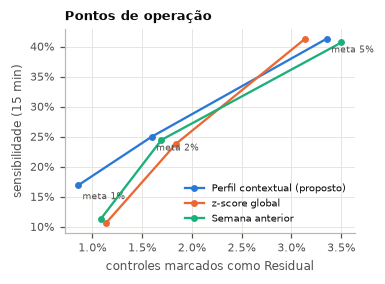

,metodo,meta,sensibilidade,sens_media_alta,especificidade,sens_latencia,acuracia_indicador
0,Perfil contextual (proposto),0.01,0.169,0.255,0.991,0.014,0.963
1,Perfil contextual (proposto),0.02,0.250,0.326,0.984,0.070,0.964
2,Perfil contextual (proposto),0.05,0.413,0.508,0.966,0.270,0.962
3,z-score global,0.01,0.106,0.160,0.989,0.012,0.935
4,z-score global,0.02,0.238,0.323,0.982,0.018,0.953
5,z-score global,0.05,0.413,0.500,0.969,0.207,0.960
6,Semana anterior,0.01,0.113,0.173,0.989,0.011,0.946
7,Semana anterior,0.02,0.245,0.336,0.983,0.017,0.962
8,Semana anterior,0.05,0.407,0.501,0.965,0.151,0.960


In [9]:
p15 = P[(P["periodo"] == "L") & (P["id_periodo"] == L_PRINCIPAL)].set_index("cenario").join(cenarios.set_index("cenario")[["tipo", "motivo", "intensidade", "mes"]])
curva = []
for nome in METODOS:
    for meta in METAS_CURVA:
        partes = []
        for mes, g in p15.groupby("mes"):
            cal = calib[(nome, L_PRINCIPAL, mes, HIST_PRINCIPAL)]
            razao = z_direcional(cal["modelo"].z(g)) / cal["base"].reindex(g["recurso"]).to_numpy()
            c = max(1.0, float(np.quantile(cal["razao_cal"], 1 - meta)))
            partes.append(pd.DataFrame({"res": razao.max(axis=1) > c, "ind": razao.idxmax(axis=1).map(INDICADOR)}, index=g.index))
        d = pd.concat(partes).join(p15[["tipo", "motivo", "intensidade"]])
        inc_ = d["tipo"] == "incidente"
        det = d[inc_ & d["res"]]
        curva.append(dict(metodo=nome, meta=meta, sensibilidade=d.loc[inc_, "res"].mean(),
                          sens_media_alta=d.loc[inc_ & d["intensidade"].isin(["media", "alta"]), "res"].mean(),
                          especificidade=(~d.loc[~inc_, "res"]).mean(),
                          sens_latencia=d.loc[inc_ & (d["motivo"] == "latencia"), "res"].mean(),
                          acuracia_indicador=(det["ind"] == det["motivo"].map(lambda m: MOTIVOS[m][0])).mean()))
curva = pd.DataFrame(curva)
fig, ax = plt.subplots(figsize=(3.4, 2.4))
for i, nome in enumerate(METODOS):
    c_ = curva[curva["metodo"] == nome]
    ax.plot(1 - c_["especificidade"], c_["sensibilidade"], marker="o", ms=3.5, color=CORES[i], label=nome)
    for _, r_ in c_.iterrows():
        if nome == PROPOSTO:
            ax.annotate(f"meta {r_['meta']:.0%}", (1 - r_["especificidade"], r_["sensibilidade"]), fontsize=6,
                        xytext=(3, -9), textcoords="offset points", color=TXT2)
ax.set_xlabel("controles marcados como Residual")
ax.set_ylabel("sensibilidade (15 min)")
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=1))
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0))
ax.legend(loc="lower right", fontsize=6.3)
ax.set_title("Pontos de operação", loc="left")
salvar(fig, "fig_curva_operacao")
plt.show()
curva.round(3)

## RQ3 · Tamanho da faixa × atraso do registro

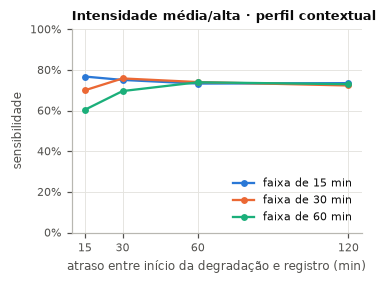

,15,30,60
atraso,,,
15.0,0.720,0.617,0.519
30.0,0.715,0.716,0.616
60.0,0.693,0.696,0.703
120.0,0.684,0.676,0.686


,15,30,60
atraso,,,
15.0,0.767,0.700,0.604
30.0,0.751,0.758,0.696
60.0,0.733,0.740,0.739
120.0,0.735,0.723,0.729


In [10]:
sa = pd.DataFrame({L: inc(T[(PROPOSTO, L)]).groupby("atraso")["residual"].mean() for L in FAIXAS_L})
sa_ma = pd.DataFrame({L: inc(T[(PROPOSTO, L)]).query("intensidade in ['media', 'alta']").groupby("atraso")["residual"].mean()
                      for L in FAIXAS_L})
fig, ax = plt.subplots(figsize=(3.4, 2.4))
for j, L in enumerate(FAIXAS_L):
    ax.plot(sa_ma.index, sa_ma[L], marker="o", ms=3.5, color=CORES[j], label=f"faixa de {L} min")
ax.set_xticks(ATRASOS)
ax.set_xlabel("atraso entre início da degradação e registro (min)")
ax.set_ylabel("sensibilidade")
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0))
ax.legend(loc="lower right")
ax.set_title("Intensidade média/alta · perfil contextual", loc="left")
salvar(fig, "fig_sens_atraso")
plt.show()
display(sa.round(3))
sa_ma.round(3)

## RQ2 · Indicador responsável (método proposto)

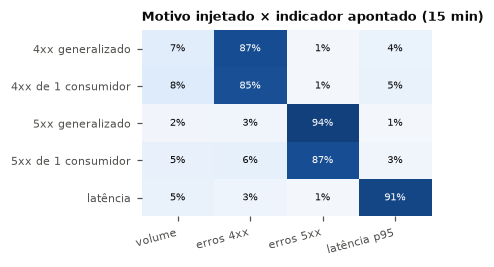

indicador,volume,erros 4xx,erros 5xx,latência p95
motivo,,,,
4xx generalizado,0.072,0.870,0.013,0.045
4xx de 1 consumidor,0.085,0.853,0.014,0.048
5xx generalizado,0.022,0.026,0.938,0.014
5xx de 1 consumidor,0.052,0.056,0.865,0.027
latência,0.050,0.031,0.014,0.905


15    89.1% [88.1%; 90.0%]
30    91.2% [90.3%; 92.0%]
60    88.4% [87.3%; 89.3%]
Name: acurácia do indicador, dtype: str

In [11]:
det15 = t15[t15["residual"]]
conf = pd.crosstab(det15["motivo"].map(NOMES_MOTIVO), det15["indicador"], normalize="index")
conf = conf.reindex(index=[NOMES_MOTIVO[m] for m in MOTIVOS], columns=list(INDICADOR.values()), fill_value=0)
acc_ind = {L: (inc(T[(PROPOSTO, L)]).query("residual")["indicador"] == inc(T[(PROPOSTO, L)]).query("residual")["esperado"]) for L in FAIXAS_L}
acc_ind_tab = pd.Series({L: fmt_ic(int(v.sum()), len(v)) for L, v in acc_ind.items()}, name="acurácia do indicador")
fig, ax = plt.subplots(figsize=(3.4, 2.2))
heatmap(ax, conf)
ax.set_xticklabels(conf.columns, rotation=15, ha="right")
ax.set_title("Motivo injetado × indicador apontado (15 min)", loc="left")
salvar(fig, "fig_confusao_indicador")
plt.show()
display(conf.round(3))
acc_ind_tab

### Abrangência (complementar)

In [12]:
Pidx = P[(P["periodo"] == "L") & (P["id_periodo"] == L_PRINCIPAL)].set_index("cenario")
d_ok = det15[det15["indicador"] == det15["esperado"]]
d_ok = d_ok[d_ok["motivo"].str.startswith(("4xx", "5xx"))]
abr = pd.Series({c: abrangencia(Pidx.loc[c], d_ok.loc[c, "indicador"]) for c in d_ok.index})
d_ok = d_ok.assign(abr_prevista=abr)
tab_abr = pd.crosstab(d_ok["motivo"].map(NOMES_MOTIVO), d_ok["abr_prevista"], normalize="index").round(2)
acc_abr = (d_ok["abr_prevista"] == d_ok["abr_esperada"])
display(tab_abr)
print("acurácia da abrangência:", fmt_ic(int(acc_abr.sum()), len(acc_abr)))

abr_prevista,consumidor específico,generalizado,indeterminada
motivo,,,
4xx de 1 consumidor,0.61,0.26,0.12
4xx generalizado,0.03,0.86,0.11
5xx de 1 consumidor,0.65,0.21,0.14
5xx generalizado,0.02,0.86,0.12


acurácia da abrangência: 76.1% [74.5%; 77.6%]


## RQ2 · Início estimado (expansão retroativa, método proposto)
Zona estimada: entre o início da última faixa residual e o fim da primeira faixa normal (em minutos antes do registro). Acerto: o início real está dentro da zona.

In [13]:
ti = inc(T[(PROPOSTO, L_PRINCIPAL)]).join(inicio)
ti = ti[ti["estado_bandas"] == "Residual"]
ti["acerto_inicio"] = (ti["atraso"] >= ti["zona_lo"]) & (ti["zona_hi"].isna() | (ti["atraso"] <= ti["zona_hi"]))
acerto_inicio = ti.groupby("atraso")["acerto_inicio"].agg(["mean", "size"])
acerto_inicio["IC 95%"] = [fmt_ic(int(round(m * n)), n) for m, n in acerto_inicio.to_numpy()]
print("acerto geral da zona de início:", fmt_ic(int(ti["acerto_inicio"].sum()), len(ti)))
zonas = ti.assign(zona=ti["zona_lo"].astype(int).astype(str) + "–" + ti["zona_hi"].fillna(-1).astype(int).astype(str).replace("-1", "mais")
                  ).groupby(["atraso", "zona"]).size().unstack(fill_value=0)
display(acerto_inicio)
zonas

acerto geral da zona de início: 83.7% [82.5%; 84.7%]


,mean,size,IC 95%
atraso,,,
15.0,0.906593,1092,90.7% [88.8%; 92.2%]
30.0,0.903404,1087,90.3% [88.4%; 92.0%]
60.0,0.790123,1053,79.0% [76.4%; 81.4%]
120.0,0.740385,1040,74.0% [71.3%; 76.6%]


zona,0–30,120–240,15–60,180–mais,30–120,60–180
atraso,,,,,,
15.0,842,9,148,19,47,27
30.0,115,21,762,37,105,47
60.0,115,47,64,59,674,94
120.0,113,104,71,86,28,638


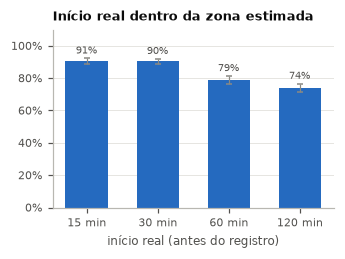

In [14]:
fig, ax = plt.subplots(figsize=(3.3, 2.1))
ax.bar(range(len(ATRASOS)), acerto_inicio["mean"], color=AZUL[4], width=0.6)
for i, (m, n) in enumerate(acerto_inicio[["mean", "size"]].to_numpy()):
    lo, hi = wilson(int(round(m * n)), n)
    ax.errorbar(i, m, yerr=[[m - lo], [hi - m]], color=TXT3, capsize=2, lw=0.8)
    ax.text(i, hi + 0.03, f"{m:.0%}", ha="center", fontsize=6.8, color=TXT2)
ax.set_xticks(range(len(ATRASOS)))
ax.set_xticklabels([f"{a} min" for a in ATRASOS])
ax.set_xlabel("início real (antes do registro)")
ax.set_ylim(0, 1.1)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0))
ax.set_title("Início real dentro da zona estimada", loc="left")
ax.grid(axis="x", visible=False)
salvar(fig, "fig_inicio")
plt.show()

### Exemplo de expansão retroativa

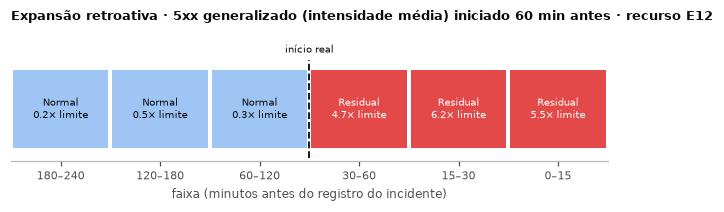

In [15]:
cand = ti[(ti["motivo"] == "5xx_geral") & (ti["atraso"] == 60) & ti["acerto_inicio"] & (ti["intensidade"] == "media")]
if cand.empty:
    cand = ti[ti["acerto_inicio"] & (ti["atraso"] >= 30)]
c_ex = cand.index[0]
b_ex = bandas[bandas["cenario"] == c_ex].sort_values("id_periodo")
cal_by_L = {L: calib[(PROPOSTO, L, cen_mes[c_ex], HIST_PRINCIPAL)] for L in FAIXAS_L}
vezes_ex = [decidir(b_ex[b_ex["id_periodo"] == i], cal_by_L[int(b_ex.loc[b_ex["id_periodo"] == i, "L"].iloc[0])])[2].max(axis=1).iloc[0]
            for i in b_ex["id_periodo"]]
fig, ax = plt.subplots(figsize=(7.0, 1.55))
nb = len(BANDAS)
atraso_ex = int(cenarios.set_index("cenario").loc[c_ex, "atraso"])
for k, ((lo, hi), res_b, v) in enumerate(zip(BANDAS, b_ex["residual"], vezes_ex)):
    x = nb - 1 - k  # mais antiga à esquerda, registro à direita
    ax.barh(0, 0.96, left=x + 0.02, height=0.6, color=CORES[7] if res_b else AZUL[1])
    ax.text(x + 0.5, 0, f"{'Residual' if res_b else 'Normal'}\n{v:.1f}× limite", ha="center", va="center", fontsize=6.5,
            color="white" if res_b else TXT1)
    if lo < atraso_ex <= hi:  # posição do início real dentro da faixa
        xr = x + 1 - (atraso_ex - lo) / (hi - lo)
        ax.plot([xr, xr], [-0.38, 0.38], color=TXT1, lw=1.2, ls="--")
        ax.text(xr, 0.42, "início real", fontsize=6.5, ha="center", va="bottom")
ax.set_xlim(0, nb)
ax.set_ylim(-0.4, 0.62)
ax.set_xticks([nb - 0.5 - k for k in range(nb)])
ax.set_xticklabels([f"{lo}–{hi}" for lo, hi in BANDAS])
ax.set_xlabel("faixa (minutos antes do registro do incidente)")
ax.set_yticks([])
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.set_title(f"Expansão retroativa · 5xx generalizado (intensidade média) iniciado {atraso_ex} min antes · recurso "
             f"{rot(cenarios.set_index('cenario').loc[c_ex, 'recurso'])}", loc="left")
salvar(fig, "fig_expansao_exemplo")
plt.show()

## Por recurso (método proposto, 15 min)

In [16]:
por_rec = pd.DataFrame({
    "sensibilidade": inc(T[(PROPOSTO, 15)]).groupby("recurso")["residual"].mean(),
    "sens. média/alta": inc(T[(PROPOSTO, 15)]).query("intensidade in ['media', 'alta']").groupby("recurso")["residual"].mean(),
    "especificidade": (~ctl(T[(PROPOSTO, 15)])["residual"]).groupby(ctl(T[(PROPOSTO, 15)])["recurso"]).mean(),
    "acurácia indicador": det15.assign(ok=det15["indicador"] == det15["esperado"]).groupby("recurso")["ok"].mean(),
})
por_rec.index = por_rec.index.map(rot)
por_rec = por_rec.sort_index()
por_rec.round(2)

,sensibilidade,sens. média/alta,especificidade,acurácia indicador
recurso,,,,
E01,0.88,0.94,0.74,0.94
E02,0.32,0.37,0.82,0.56
E03,0.71,0.73,0.55,0.69
E04,0.85,0.89,0.71,0.85
E05,0.93,0.96,0.80,0.96
E06,0.22,0.18,0.91,0.70
E07,0.70,0.80,0.85,0.95
E08,0.69,0.76,0.86,0.93
E09,0.90,0.94,0.72,0.90


## Histórico de 3 meses × 1 mês (método proposto)
Mesmos cenários, modelo ajustado com os 3 meses ou só com o mês anterior ao teste. McNemar sobre os acertos de estado.

In [17]:
hist_tab = []
for L in FAIXAS_L:
    for h in HISTORICOS:
        t = T_all[(PROPOSTO, L, h)]
        i, c = inc(t), ctl(t)
        ima = i[i["intensidade"].isin(["media", "alta"])]
        det = i[i["residual"]]
        hist_tab.append(dict(L=L, historico=h, sensibilidade=fmt_ic(int(i["residual"].sum()), len(i)),
                             sens_media_alta=fmt_ic(int(ima["residual"].sum()), len(ima)),
                             especificidade=fmt_ic(int((~c["residual"]).sum()), len(c)),
                             acuracia_indicador=f"{(det['indicador'] == det['esperado']).mean():.1%}",
                             sens=i["residual"].mean(), sens_ma=ima["residual"].mean(), espec=(~c["residual"]).mean()))
    a3, a1 = T_all[(PROPOSTO, L, "3m")]["acerto_estado"], T_all[(PROPOSTO, L, "1m")]["acerto_estado"]
    n01, n10, pv = mcnemar(a3, a1.loc[a3.index])
    hist_tab[-1]["mcnemar_3m_vs_1m"] = f"só 3m acerta {n01} · só 1m acerta {n10} · p = {pv:.3g}"
hist_tab = pd.DataFrame(hist_tab)
display(hist_tab.drop(columns=["sens", "sens_ma", "espec"]))
por_mes_hist = pd.concat({h: T_all[(PROPOSTO, 15, h)].groupby(["mes", "tipo"])["acerto_estado"].mean().unstack() for h in HISTORICOS}, axis=1)
por_mes_hist.columns = [f"{h} · {'sensibilidade' if t == 'incidente' else 'especificidade'}" for h, t in por_mes_hist.columns]
por_mes_hist.round(3)

,L,historico,sensibilidade,sens_media_alta,especificidade,acuracia_indicador,mcnemar_3m_vs_1m
0,15,3m,70.3% [69.1%; 71.4%],74.6% [73.2%; 76.0%],79.1% [78.1%; 80.1%],89.1%,NaN
1,15,1m,72.6% [71.5%; 73.7%],75.9% [74.5%; 77.2%],75.1% [74.0%; 76.2%],87.8%,só 3m acerta 666 · só 1m acerta 562 · p = 0.00327
2,30,3m,67.6% [66.5%; 68.8%],73.0% [71.6%; 74.4%],81.5% [80.5%; 82.5%],91.2%,NaN
3,30,1m,70.6% [69.4%; 71.7%],74.5% [73.1%; 75.9%],77.1% [76.0%; 78.1%],88.9%,só 3m acerta 659 · só 1m acerta 568 · p = 0.0102
4,60,3m,63.1% [61.9%; 64.3%],69.2% [67.7%; 70.7%],81.9% [80.9%; 82.8%],88.4%,NaN
5,60,1m,66.5% [65.3%; 67.7%],71.9% [70.5%; 73.3%],77.1% [76.0%; 78.1%],86.0%,só 3m acerta 716 · só 1m acerta 632 · p = 0.0237


,3m · especificidade,3m · sensibilidade,1m · especificidade,1m · sensibilidade
mes,,,,
ago,0.791,0.806,0.737,0.825
set,0.792,0.643,0.759,0.669


/tmp/ipykernel_822745/680614555.py:24: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


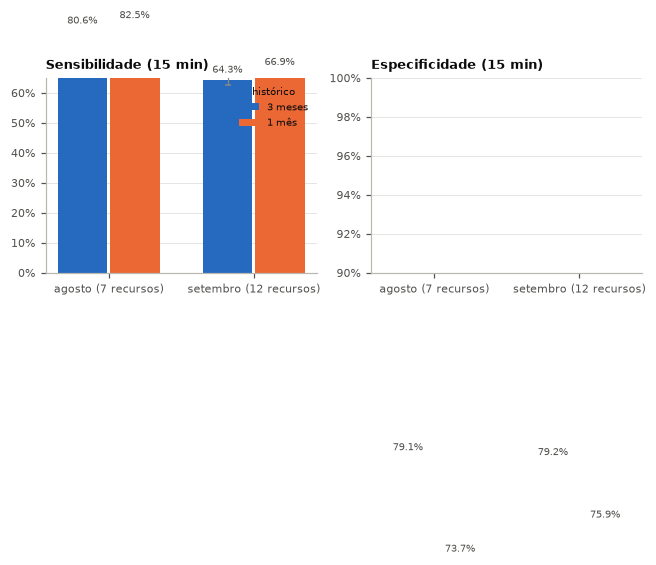

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.3))
for ax, (tipo, titulo) in zip(axes, [("incidente", "Sensibilidade (15 min)"), ("controle", "Especificidade (15 min)")]):
    for j, h in enumerate(HISTORICOS):
        t_ = T_all[(PROPOSTO, 15, h)]
        for i, mes in enumerate(MESES_TESTE):
            g = t_[(t_["mes"] == mes) & (t_["tipo"] == tipo)]
            k, n = int(g["acerto_estado"].sum()), len(g)
            p_ = k / n
            lo, hi = wilson(k, n)
            x = i + (j - 0.5) * 0.36
            ax.bar(x, p_, width=0.34, color=[AZUL[4], CORES[1]][j], label=("3 meses" if h == "3m" else "1 mês") if i == 0 else None)
            ax.errorbar(x, p_, yerr=[[p_ - lo], [hi - p_]], color=TXT3, capsize=2, lw=0.8)
            ax.text(x, hi + (0.01 if tipo == "incidente" else 0.002), f"{p_:.1%}", ha="center", fontsize=6.3, color=TXT2)
    ax.set_xticks(range(len(MESES_TESTE)))
    ax.set_xticklabels(["agosto (7 recursos)", "setembro (12 recursos)"])
    ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0))
    ax.set_title(titulo, loc="left")
    ax.grid(axis="x", visible=False)
    if tipo == "controle":
        ax.set_ylim(0.9, 1.0)
    else:
        ax.set_ylim(0, 0.65)
axes[0].legend(title="histórico", loc="upper right", fontsize=6.5, title_fontsize=6.5)
fig.tight_layout()
salvar(fig, "fig_historico")
plt.show()

## Resultado por mês de teste (proposto, 3 meses, 15 min)
Agosto tem 7 recursos; setembro tem os 12. Para comparar o mesmo conjunto de recursos, também se mostra setembro só com os 7 de agosto.

In [19]:
t = T[(PROPOSTO, 15)]
rec_ago = set(t.loc[t["mes"] == "ago", "recurso"])
grupos = {"agosto (7 recursos)": t["mes"] == "ago", "setembro (12 recursos)": t["mes"] == "set",
          "setembro (mesmos 7)": (t["mes"] == "set") & t["recurso"].isin(rec_ago)}
por_mes = []
for nome_g, m in grupos.items():
    g = t[m]
    i, c = inc(g), ctl(g)
    ima = i[i["intensidade"].isin(["media", "alta"])]
    det = i[i["residual"]]
    por_mes.append(dict(grupo=nome_g, sensibilidade=fmt_ic(int(i["residual"].sum()), len(i)),
                        sens_media_alta=fmt_ic(int(ima["residual"].sum()), len(ima)),
                        especificidade=fmt_ic(int((~c["residual"]).sum()), len(c)),
                        acuracia_indicador=fmt_ic(int((det["indicador"] == det["esperado"]).sum()), len(det))))
por_mes = pd.DataFrame(por_mes)
por_mes

,grupo,sensibilidade,sens_media_alta,especificidade,acuracia_indicador
0,agosto (7 recursos),80.6% [78.9%; 82.2%],85.7% [83.8%; 87.4%],79.1% [77.3%; 80.7%],93.2% [92.0%; 94.3%]
1,setembro (12 recursos),64.3% [62.8%; 65.8%],68.2% [66.3%; 70.0%],79.2% [77.9%; 80.4%],86.1% [84.6%; 87.4%]
2,setembro (mesmos 7),82.5% [80.8%; 84.0%],88.0% [86.2%; 89.6%],76.9% [75.1%; 78.6%],91.0% [89.6%; 92.2%]


## Latência ×10: justificativa e efeito
Distribuição, no histórico, da razão entre o p95 horário e a mediana do seu contexto (recurso × tipo de dia × hora).

In [20]:
j1 = recortar(pd.read_parquet(RESULTADOS / "02_janelas_60min.parquet"), TREINO)
med_ctx = j1.groupby(["recurso", "tipo_dia", "hora"])["lat_p95"].transform("median")
razao_lat = (j1["lat_p95"] / med_ctx).dropna()
lat_real = pd.Series({"p99": razao_lat.quantile(0.99), "p99,9": razao_lat.quantile(0.999), "máximo": razao_lat.max(),
                      "horas ≥ 4×": (razao_lat >= 4).mean(), "horas ≥ 10×": (razao_lat >= 10).mean()})
display(lat_real.round(4))
sens_lat = inc(t)[inc(t)["motivo"] == "latencia"].groupby("intensidade")["residual"].agg(["mean", "size"]).reindex(INTENSIDADES)
sens_lat["IC 95%"] = [fmt_ic(int(round(m * n)), int(n)) for m, n in sens_lat[["mean", "size"]].to_numpy()]
sens_lat

p99             8.7627
p99,9          25.2474
máximo         67.5333
horas ≥ 4×      0.0231
horas ≥ 10×     0.0078
dtype: float64

,mean,size,IC 95%
intensidade,,,
baixa,0.363158,380,36.3% [31.6%; 41.3%]
media,0.692105,380,69.2% [64.4%; 73.6%]
alta,0.844737,380,84.5% [80.5%; 87.8%]
muito_alta,0.936842,380,93.7% [90.8%; 95.7%]


## Critérios de sucesso

In [21]:
r15 = resumo[(resumo["metodo"] == PROPOSTO) & (resumo["L"] == 15)].iloc[0]
acc15 = acc_ind[15]
p_min = mc[(mc["L"] == 15)]
perde = ((p_min["so_baseline_acerta"] > p_min["so_proposto_acerta"]) & (p_min["p"] < 0.05)).any()
criterios = pd.DataFrame([
    ("Controles com saída Normal ≥ 95%", f"{r15['espec']:.1%}", r15["espec"] >= 0.95),
    ("Sensibilidade 15 min, intensidade média/alta ≥ 70%", f"{r15['sens_ma']:.1%}", r15["sens_ma"] >= 0.70),
    ("Acurácia do indicador ≥ 90%", f"{acc15.mean():.1%}", acc15.mean() >= 0.90),
    ("Início real na zona estimada ≥ 70%", f"{ti['acerto_inicio'].mean():.1%}", ti["acerto_inicio"].mean() >= 0.70),
    ("Sem perda significativa para baselines (McNemar)", "sim" if not perde else "não", not perde),
], columns=["critério", "resultado", "atendido"])
criterios

,critério,resultado,atendido
0,Controles com saída Normal ≥ 95%,79.1%,False
1,"Sensibilidade 15 min, intensidade média/alta ≥...",74.6%,True
2,Acurácia do indicador ≥ 90%,89.1%,False
3,Início real na zona estimada ≥ 70%,83.7%,True
4,Sem perda significativa para baselines (McNemar),não,False


In [22]:
P.to_parquet(RESULTADOS / "06_periodos.parquet", index=False)
pd.concat({f"{n} | {L} | {h}": t for (n, L, h), t in T_all.items()}).to_parquet(RESULTADOS / "06_decisoes.parquet")
hist_tab.to_csv(RESULTADOS / "06_historico_3m_1m.csv", index=False)
por_mes_hist.to_csv(RESULTADOS / "06_por_mes_historico.csv")
por_mes.to_csv(RESULTADOS / "06_por_mes.csv", index=False)
lat_real.to_csv(RESULTADOS / "06_latencia_real.csv")
sens_lat.to_csv(RESULTADOS / "06_sens_latencia.csv")
resumo.to_csv(RESULTADOS / "06_resumo.csv", index=False)
mc.to_csv(RESULTADOS / "06_mcnemar.csv", index=False)
sm.to_csv(RESULTADOS / "06_sens_motivo.csv")
sa.to_csv(RESULTADOS / "06_sens_atraso.csv")
sa_ma.to_csv(RESULTADOS / "06_sens_atraso_media_alta.csv")
conf.to_csv(RESULTADOS / "06_confusao_indicador.csv")
acc_ind_tab.to_csv(RESULTADOS / "06_acuracia_indicador.csv")
tab_abr.to_csv(RESULTADOS / "06_abrangencia.csv")
acerto_inicio.to_csv(RESULTADOS / "06_inicio.csv")
zonas.to_csv(RESULTADOS / "06_zonas_inicio.csv")
por_rec.to_csv(RESULTADOS / "06_por_recurso.csv")
criterios.to_csv(RESULTADOS / "06_criterios.csv", index=False)
curva.to_csv(RESULTADOS / "06_curva_operacao.csv", index=False)
salvar_json(dict(incidentes_sem_trafego=len(sem_traf), acuracia_abrangencia=float(acc_abr.mean()), n_abrangencia=int(len(acc_abr)),
                 acerto_inicio=float(ti["acerto_inicio"].mean()), n_inicio=int(len(ti)),
                 cenario_exemplo=int(c_ex)), "06_resumo.json")
print("resultados salvos")

resultados salvos
